# Figure 4.4 sketch: exported susceptibility map and legend

Makes the sketch used in Section 4.4 from the labeled grid that `insar_label.ipynb` wrote
(`data/subsidence_dataset_processed.csv`). Run the cells from top to bottom. The picture is saved to
`figures/fig_4_4_sketch.png`.

What is real and what is not:
- the map cells, the five classes and the cell counts come from the labeled grid;
- the well dots are **illustrative** (random cells) unless you point `WELLS_CSV` at a real wells file;
- it is a mockup of what the manager would see in QGIS, not model output.

## Settings

In [11]:
import hashlib, json
from pathlib import Path
import pandas as pd

A   = Path("data/subsidence_dataset_processed.csv")   # the file you want to check (your repo copy)
B   = None                           # another copy to compare it with (optional; set to None to skip)
LOG = Path("data/label_build_log.json")                # written by insar_label.ipynb

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# 1) the file against the checksum your own notebook recorded
a_hash = sha256(A)
logged = json.loads(LOG.read_text())["output_csv"]
print(f"{A.name}\n  sha256 now : {a_hash}\n  in the log : {logged['sha256']}\n  rows x cols in the log: {logged['rows']} x {logged['cols']}")
print("  checksum matches the log:", a_hash == logged["sha256"])

# 2) a second copy against the first
if B is not None:
    b_hash = sha256(B)
    da, db = pd.read_csv(A), pd.read_csv(B)
    print(f"\n{B.name}\n  sha256     : {b_hash}")
    print("  identical bytes          :", a_hash == b_hash)
    print("  same shape               :", da.shape, db.shape)
    print("  same values (all cells)  :", da.equals(db))
    ra, rb = A.read_bytes(), B.read_bytes()
    print("  line breaks (CRLF) in A / B           :", ra.count(b"\r\n"), "/", rb.count(b"\r\n"))
    print("  file ends with a line break, A / B     :", ra.endswith(b"\n"), "/", rb.endswith(b"\n"))
    print("  size in bytes, A / B                   :", len(ra), "/", len(rb))

subsidence_dataset_processed.csv
  sha256 now : ad033f34e110042e193ef9135dcae13e5905e9a487d2b881265aa53dc35cbd50
  in the log : ad033f34e110042e193ef9135dcae13e5905e9a487d2b881265aa53dc35cbd50
  rows x cols in the log: 5192 x 37
  checksum matches the log: True


In [14]:
from pathlib import Path

DATA      = Path("data/subsidence_dataset_processed.csv")   # written by insar_label.ipynb
OUT_PNG   = Path("figures/fig_4_4_sketch.png")

# Optional: a CSV of real wells with longitude/latitude columns. Leave as None to draw
# 12 illustrative wells (the legend and subtitle then say "illustrative").
WELLS_CSV = None            # e.g. Path("data/wells.csv")
WELL_LON, WELL_LAT = "longitude", "latitude"

N_FAKE_WELLS = 12
FAKE_SEED    = 3
WINDOW_TEXT  = "2020\u20132024"   # shown in the bottom banner

## Step 1. Load the labeled grid and count the cells in each state

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch

need = ["longitude", "latitude", "susceptibility_class", "insar_n_points"]

def has_labels(p):
    try:
        return set(need) <= set(pd.read_csv(p, nrows=0).columns)
    except Exception:
        return False

print("Notebook is running in:", Path.cwd().resolve())
if not DATA.exists():
    raise RuntimeError(f"{DATA.resolve()} not found. Put this notebook in the repo folder (next to data/), "
                       "or fix DATA in Settings.")

if not has_labels(DATA):
    cols = list(pd.read_csv(DATA, nrows=0).columns)
    print(f"{DATA.resolve()} has {len(cols)} columns and no label columns "
          f"(susceptibility_class, insar_n_points). It is the version from before the label was added.")
    # look for a copy that does have the label, in this folder and its parent
    found = []
    here = Path.cwd().resolve()
    for root, depth in ((here, 3), (here.parent, 2)):          # a few levels only, so this stays fast
        for k in range(depth + 1):
            for p in root.glob("*/" * k + DATA.name):
                if p.resolve() != DATA.resolve() and has_labels(p):
                    found.append(p.resolve())
    found = sorted(set(found))
    if len(found) == 1:
        print("Found one copy with the label columns and using it:", found[0])
        DATA = found[0]
    else:
        if found:
            print("Copies with the label columns:", *found, sep="\n  ")
        raise RuntimeError(
            "No usable labeled grid. Open insar_label.ipynb, set CONFIRMED_UNITS_AND_SIGN = True in its "
            "Settings cell, and run it to the end (Step 3 rewrites data/subsidence_dataset_processed.csv with "
            "the label columns, 37 columns in total). Then run this notebook again. If the labeled file is in "
            "another folder, set DATA in Settings to its full path.")

d = pd.read_csv(DATA)
print("Using", DATA.resolve(), d.shape)

LABELS = ["very_low", "low", "moderate", "high", "very_high"]
PRETTY = ["Very low", "Low", "Moderate", "High", "Very high"]

lab    = d["susceptibility_class"].notna()
n_nolab = int((~lab).sum())
n_low   = int((lab & (d["insar_n_points"] < 3)).sum())
n_med   = int((lab & d["insar_n_points"].between(3, 4)).sum())
n_high  = int((lab & (d["insar_n_points"] >= 5)).sum())
assert n_low + n_med + n_high == int(lab.sum()), "confidence groups do not add up to the labeled cells"

print(f"{len(d):,} cells in the grid")
print(f"  no InSAR label : {n_nolab:,}")
print(f"  labeled        : {int(lab.sum()):,}  (high {n_high:,}, medium {n_med:,}, low {n_low:,})")
print(d.loc[lab, "susceptibility_class"].value_counts().reindex(LABELS).to_string())

Notebook is running in: C:\Users\m.rahaman\Downloads\Fall 2026\AI Systems\subsidence-susceptibility-mapping
Using C:\Users\m.rahaman\Downloads\Fall 2026\AI Systems\subsidence-susceptibility-mapping\data\subsidence_dataset_processed.csv (5192, 37)
5,192 cells in the grid
  no InSAR label : 1,653
  labeled        : 3,539  (high 2,088, medium 586, low 865)
susceptibility_class
very_low     711
low          684
moderate     703
high         672
very_high    769


## Step 2. Draw the sketch

Colors are a five-step blue ramp (light to dark = lower to higher susceptibility). Grey is a cell with no label.
A diagonal slash marks a cell that rests on fewer than 3 InSAR points. The slash is dark on the two lightest
classes and light on the others so it stays visible.

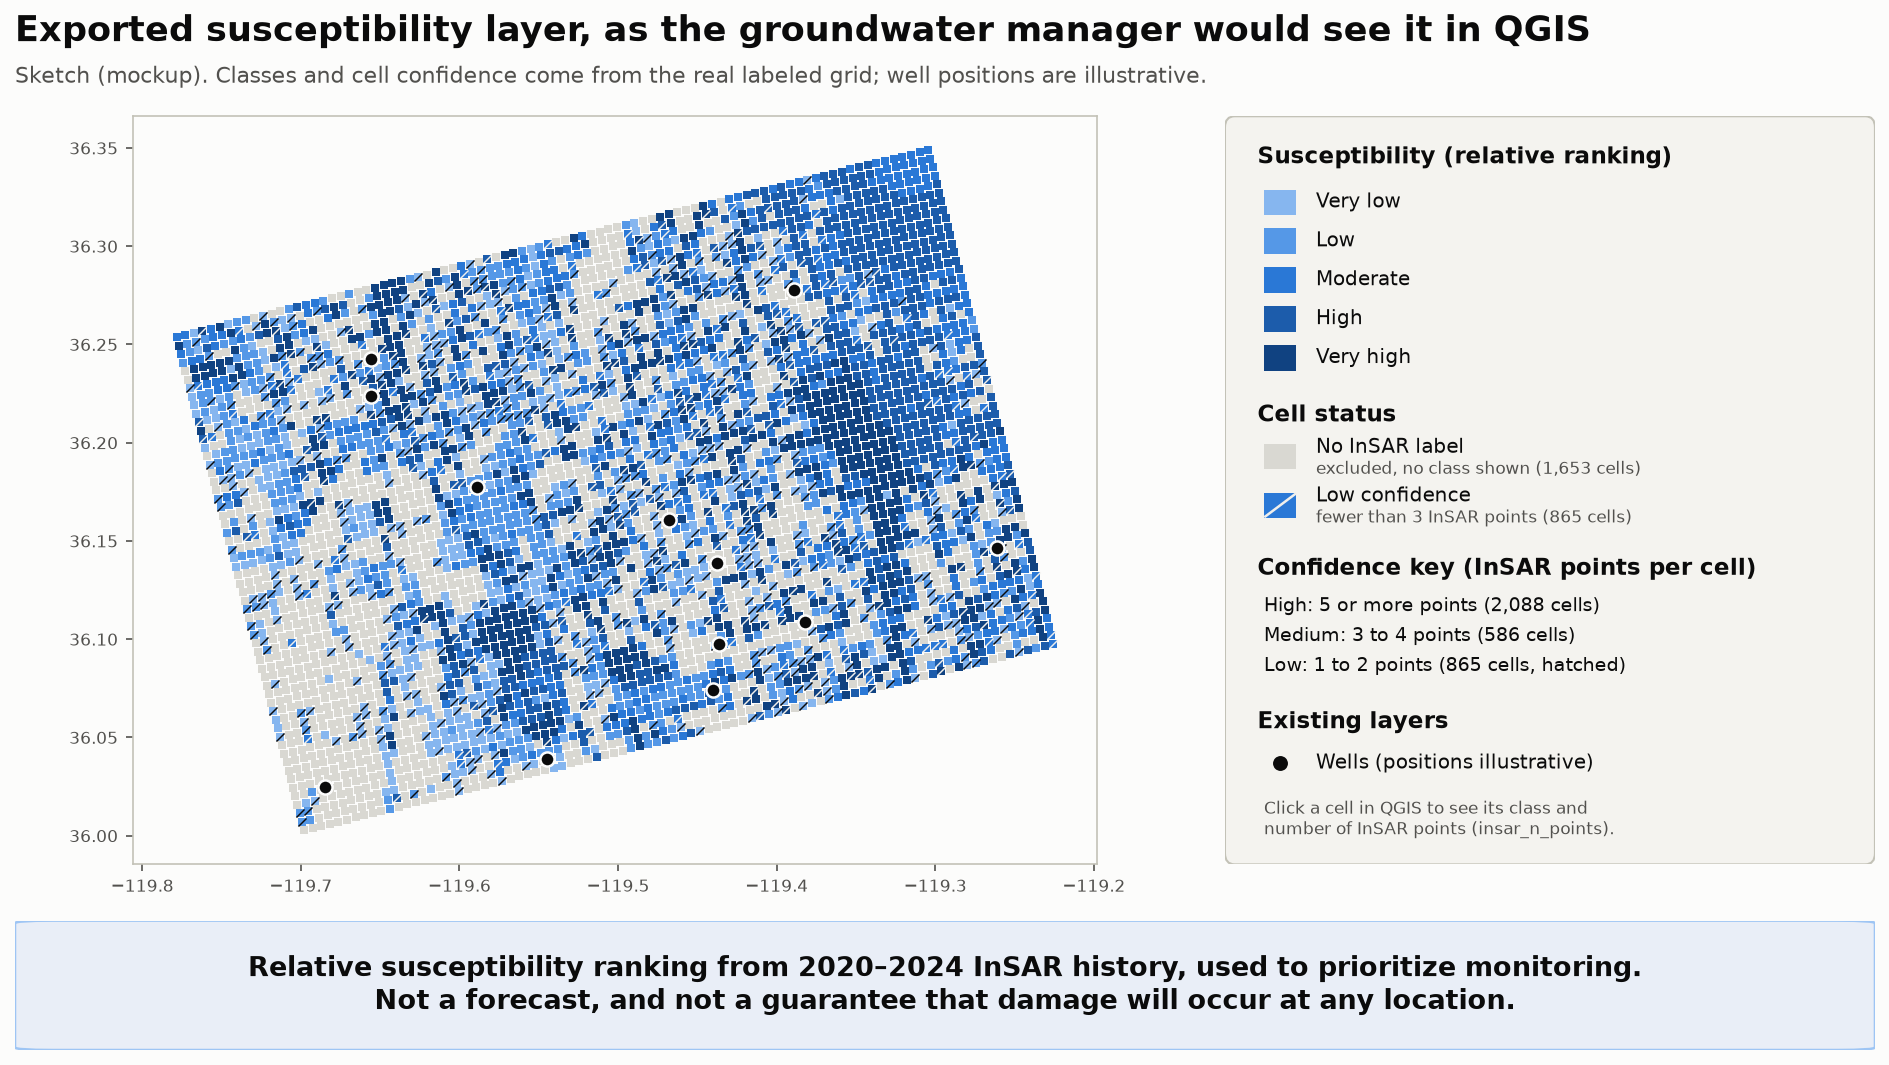

saved C:\Users\m.rahaman\Downloads\Fall 2026\AI Systems\subsidence-susceptibility-mapping\figures\fig_4_4_sketch.png


In [16]:
SURFACE, INK, INK2, GRAY, LINE = "#fcfcfb", "#0b0b0b", "#52514e", "#d9d8d2", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]

# wells: real if a file is given, otherwise illustrative
if WELLS_CSV is not None:
    wl = pd.read_csv(WELLS_CSV)
    wells_x, wells_y = wl[WELL_LON].to_numpy(), wl[WELL_LAT].to_numpy()
    wells_label = "Wells"
    subtitle = "Sketch (mockup). Classes and cell confidence come from the real labeled grid; wells are from the wells file."
else:
    rng = np.random.default_rng(FAKE_SEED)
    w = d.iloc[rng.choice(len(d), N_FAKE_WELLS, replace=False)]
    wells_x, wells_y = w["longitude"].to_numpy() + 0.004, w["latitude"].to_numpy() - 0.003
    wells_label = "Wells (positions illustrative)"
    subtitle = "Sketch (mockup). Classes and cell confidence come from the real labeled grid; well positions are illustrative."

fig = plt.figure(figsize=(13.333, 7.5), dpi=150, facecolor=SURFACE)
fig.text(0.035, 0.945, "Exported susceptibility layer, as the groundwater manager would see it in QGIS",
         fontsize=17, weight="bold", color=INK, va="center")
fig.text(0.035, 0.905, subtitle, fontsize=10.5, color=INK2, va="center")

# ---- map ----
ax = fig.add_axes([0.05, 0.205, 0.57, 0.665], facecolor=SURFACE)
ax.set_aspect(1 / np.cos(np.deg2rad(d["latitude"].mean())))
S = 15                                                    # marker size; raise it if the cells look too sparse
un = d[~lab]
ax.scatter(un["longitude"], un["latitude"], s=S, marker="s", color=GRAY, linewidths=0)
for name, col in zip(LABELS, RAMP):
    sub = d[d["susceptibility_class"] == name]
    ax.scatter(sub["longitude"], sub["latitude"], s=S, marker="s", color=col, linewidths=0)
low = d[lab & (d["insar_n_points"] < 3)]
for name in LABELS:
    sub = low[low["susceptibility_class"] == name]
    slash = INK if name in ("very_low", "low") else "#f0efec"
    ax.scatter(sub["longitude"], sub["latitude"], s=S, marker=[(-1, -1), (1, 1)], edgecolor=slash, linewidths=0.7)
ax.scatter(wells_x, wells_y, s=46, marker="o", color=INK, edgecolor=SURFACE, linewidths=1.2, zorder=5)
ax.tick_params(labelsize=8, colors=INK2)
for s in ax.spines.values():
    s.set_color(LINE)

# ---- legend panel (drawn in its own axes) ----
pan = fig.add_axes([0.64, 0.205, 0.325, 0.665]); pan.set_xlim(0, 1); pan.set_ylim(0, 1); pan.axis("off")
pan.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.015",
                             facecolor="#f4f3ef", edgecolor=LINE, linewidth=1, transform=pan.transAxes))
def head(y, t):
    pan.text(0.05, y, t, fontsize=11, weight="bold", color=INK, va="center")
def swatch(y, col, label, sub=None, hatch=False, circle=False):
    if circle:
        pan.scatter([0.085], [y], s=70, color=INK, edgecolor="#f4f3ef", linewidths=1.2)
    else:
        pan.add_patch(Rectangle((0.06, y - 0.017), 0.05, 0.034, facecolor=col, edgecolor="none"))
        if hatch:
            pan.plot([0.062, 0.108], [y - 0.015, y + 0.015], color="#f0efec", lw=1.2)
    pan.text(0.14, y + (0.012 if sub else 0), label, fontsize=9.5, color=INK, va="center")
    if sub:
        pan.text(0.14, y - 0.017, sub, fontsize=8.2, color=INK2, va="center")

head(0.945, "Susceptibility (relative ranking)")
for i, (c, n) in enumerate(zip(RAMP, PRETTY)):
    swatch(0.885 - i * 0.052, c, n)
head(0.60, "Cell status")
swatch(0.545, GRAY, "No InSAR label", f"excluded, no class shown ({n_nolab:,} cells)")
swatch(0.480, RAMP[2], "Low confidence", f"fewer than 3 InSAR points ({n_low:,} cells)", hatch=True)
head(0.395, "Confidence key (InSAR points per cell)")
pan.text(0.06, 0.345, f"High: 5 or more points ({n_high:,} cells)",  fontsize=9, color=INK, va="center")
pan.text(0.06, 0.305, f"Medium: 3 to 4 points ({n_med:,} cells)",   fontsize=9, color=INK, va="center")
pan.text(0.06, 0.265, f"Low: 1 to 2 points ({n_low:,} cells, hatched)", fontsize=9, color=INK, va="center")
head(0.19, "Existing layers")
swatch(0.135, None, wells_label, circle=True)
pan.text(0.06, 0.06, "Click a cell in QGIS to see its class and\nnumber of InSAR points (insar_n_points).",
         fontsize=8.2, color=INK2, va="center")

# ---- bottom banner: the framing the manager must see ----
bn = fig.add_axes([0.035, 0.04, 0.93, 0.115]); bn.axis("off"); bn.set_xlim(0, 1); bn.set_ylim(0, 1)
bn.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.02",
                            facecolor="#e9eef7", edgecolor="#9ec5f4", linewidth=1.2, transform=bn.transAxes))
bn.text(0.5, 0.5, f"Relative susceptibility ranking from {WINDOW_TEXT} InSAR history, used to prioritize monitoring.\n"
                  "Not a forecast, and not a guarantee that damage will occur at any location.",
        ha="center", va="center", fontsize=13, weight="bold", color=INK)

OUT_PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_PNG, dpi=150, facecolor=SURFACE)
plt.show()
print("saved", OUT_PNG.resolve())

## Put it in the Word document

In Word, right-click the Figure 4.4 picture, choose **Change Picture > From a File**, and pick `figures/fig_4_4_sketch.png`.
The numbers in the legend (1,653 / 865 / 2,088 / 586) come from your own run, so they should match Section 6.4.
If you changed anything in the Settings cell, update the caption to match.